# TinyML 2026 · Del entrenamiento en Google Colab a Arduino Nano 33 BLE Sense

**Práctica guiada | Introducción al TinyML | Versión 1.0 — 26 de octubre de 2026**

**Objetivo:** entrenar una red neuronal que aproxime $y=\sin(x)$, evaluar su desempeño, cuantizarla a **INT8**, convertirla a un modelo **TensorFlow Lite (`.tflite`)**, incorporarla como un arreglo C/C++ en `model.h` y generar un **sketch para Arduino IDE 2.x** que ejecute inferencia real con TensorFlow Lite Micro.

> **Placas:** Arduino Nano 33 BLE Sense (original) y **Nano 33 BLE Sense Rev2**, así como otras placas ARM Mbed compatibles. Para una primera práctica no se usan micrófono ni IMU; por lo tanto, el cambio de sensores entre Rev1 y Rev2 no afecta a este ejemplo. La biblioteca empleada es **Chirale_TensorFlowLite 2.0.0 (2024)**, una adaptación Arduino de TFLM. Es de terceros y conviene validar la compilación con la versión de Arduino Mbed OS Nano Boards que se instale.

**Entregables automáticos de este notebook:**
- `modelo_seno_int8.tflite`: modelo cuantizado.
- `model.h`: bytes del modelo, alineados para el microcontrolador.
- `TinyML_Seno_Nano33BLE.ino`: sketch de inferencia y salida al Serial Plotter.
- `README_Arduino.txt`: instrucciones para Arduino IDE.
- `metricas.json`: parámetros de cuantización y resultados.
- `TinyML_Seno_Arduino_Nano33BLE.zip`: proyecto Arduino listo para extraer y abrir.

**No necesitas hardware durante el entrenamiento.** La carga y ejecución en Arduino se realizan después, desde tu computadora.

**Referencias:** [TFLM principal](https://github.com/tensorflow/tflite-micro) · [Chirale Arduino](https://github.com/spaziochirale/Chirale_TensorFlowLite) · [Arduino Mbed OS Nano Boards](https://docs.arduino.cc/software/ide-v1/tutorials/getting-started/cores/arduino-mbed_nano/) · [Ejemplo histórico de Hello World](https://github.com/tensorflow/tflite-micro-arduino-examples/tree/main/examples/hello_world).

## 0. Preparar el entorno de Colab

Abre este `.ipynb` en Google Colab y elige **Entorno de ejecución → Ejecutar todo**. Colab normalmente incluye TensorFlow, NumPy y Matplotlib. Si `import tensorflow` falla, ejecuta primero `!pip -q install tensorflow` y reinicia el entorno.

Para reproducibilidad fijamos semillas. La versión de TensorFlow del entorno se imprime para registrar qué herramienta generó el FlatBuffer; **TFLM en Arduino y TensorFlow de Colab no son exactamente la misma biblioteca**.

In [10]:
import sys, json, math, zipfile, textwrap
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 2026
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT = Path('/tinyml_seno') if Path('/content').is_dir() else Path('tinyml_seno')
OUTPUT.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('NumPy:', np.__version__)
print('Archivos en:', OUTPUT.resolve())

Python: 3.11.17
TensorFlow: 2.21.0
NumPy: 2.4.6
Archivos en: /home/jrgels/Documents/Maestria PCIC/3er Semestre/TinyML/Tareas/TinyML2/notebooks/tinyml_seno


## 1. Preparación de datos

Entrenaremos con pares $(x,\sin(x))$, usando $x\in[0,2\pi]$ y una pequeña perturbación en la salida de entrenamiento. **Evaluaremos contra el seno exacto** en una rejilla independiente; así no confundiremos el ruido artificial con error del modelo.

La entrada del modelo tiene forma `(N, 1)` y su salida también. Estas formas son relevantes al programar los tensores de TFLM.

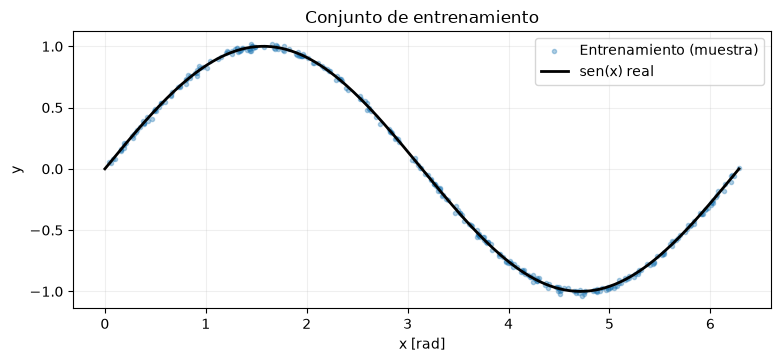

Formas: (1600, 1) (1600, 1) (320, 1) (256, 1)


In [11]:
rng = np.random.default_rng(SEED)
X_train = rng.uniform(0.0, 2*np.pi, size=(1600, 1)).astype(np.float32)
y_train = (np.sin(X_train) + rng.normal(0, 0.015, size=(1600, 1))).astype(np.float32)
X_val = rng.uniform(0.0, 2*np.pi, size=(320, 1)).astype(np.float32)
y_val = np.sin(X_val).astype(np.float32)
X_test = np.linspace(0, 2*np.pi, 256, dtype=np.float32).reshape(-1, 1)
y_test = np.sin(X_test).astype(np.float32)

plt.figure(figsize=(9, 3.6))
plt.scatter(X_train[::5, 0], y_train[::5, 0], s=9, alpha=0.35, label='Entrenamiento (muestra)')
plt.plot(X_test[:, 0], y_test[:, 0], color='black', linewidth=2, label='sen(x) real')
plt.xlabel('x [rad]'); plt.ylabel('y'); plt.title('Conjunto de entrenamiento')
plt.legend(); plt.grid(alpha=.2); plt.show()
print('Formas:', X_train.shape, y_train.shape, X_val.shape, X_test.shape)

## 2. Definir y entrenar el modelo

Una red pequeña **1 → 16 → 16 → 1**, con activaciones `tanh`, basta para ilustrar la aproximación de una función continua. La red se entrena **en la nube**; Arduino solo ejecutará inferencia.

`EarlyStopping` detiene el entrenamiento si deja de mejorar el error de validación. El número real de épocas depende de la ejecución.

Model: "seno_tinyml"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 965 (3.77 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644 (2.52 KB)

Épocas ejecutadas: 118


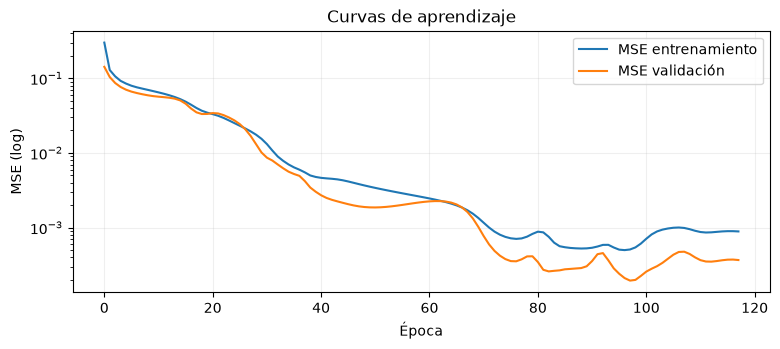

In [12]:
# NUEVO Reestablecer semillas antes de crear el modelo (Entrenamiento del modelo reproducible)
SEED = 2026
tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,), dtype=tf.float32),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(1),
], name='seno_tinyml')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae'],
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )],
)
model.summary()
print('Épocas ejecutadas:', len(history.history['loss']))
plt.figure(figsize=(9, 3.4))
plt.plot(history.history['loss'], label='MSE entrenamiento')
plt.plot(history.history['val_loss'], label='MSE validación')
plt.yscale('log'); plt.xlabel('Época'); plt.ylabel('MSE (log)')
plt.title('Curvas de aprendizaje'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 3. Evaluar el modelo de TensorFlow (float32)

Calculamos RMSE y MAE sobre una rejilla de prueba separada. Estos resultados son la referencia para medir la pérdida ocasionada por la cuantización.

Modelo float32: {
  "RMSE": 0.013900681398808956,
  "MAE": 0.011784043163061142,
  "Error_max": 0.03746974840760231
}


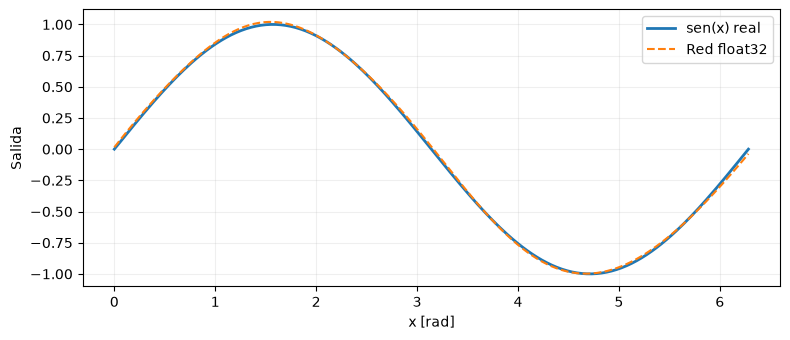

In [13]:
pred_fp32 = model.predict(X_test, verbose=0).reshape(-1)
y_true = y_test.reshape(-1)

def error_metrics(reference, prediction):
    return {
        'RMSE': float(np.sqrt(np.mean((reference - prediction)**2))),
        'MAE': float(np.mean(np.abs(reference - prediction))),
        'Error_max': float(np.max(np.abs(reference - prediction))),
    }

metric_fp32 = error_metrics(y_true, pred_fp32)
print('Modelo float32:', json.dumps(metric_fp32, indent=2))
plt.figure(figsize=(9, 3.6))
plt.plot(X_test[:, 0], y_true, label='sen(x) real', linewidth=2)
plt.plot(X_test[:, 0], pred_fp32, '--', label='Red float32')
plt.xlabel('x [rad]'); plt.ylabel('Salida'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 4. Cuantización ENTERA completa (INT8)

`Optimize.DEFAULT` junto con un **representative dataset** permite calibrar activaciones. Al establecer `TFLITE_BUILTINS_INT8` y forzar entrada y salida `tf.int8`, evitamos que Arduino tenga que calcular entradas o salidas en coma flotante dentro del grafo.

**Importante:** la cuantización no se reduce a convertir bytes; en Arduino hay que aplicar las escalas y los ceros (`scale` y `zero_point`) a los datos de entrada y salida.

In [14]:
def representative_data():
    for x in np.linspace(0, 2*np.pi, 256, dtype=np.float32):
        yield [np.array([[x]], dtype=np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
model_file = OUTPUT / 'modelo_seno_int8.tflite'
model_file.write_bytes(tflite_model)
print('Tamaño del modelo INT8:', len(tflite_model), 'bytes')
print('Archivo:', model_file)

# La inspección de operadores ayuda a diagnosticar incompatibilidades con TFLM.
try:
    tf.lite.experimental.Analyzer.analyze(model_content=tflite_model)
except Exception as exc:
    print('La visualización de operadores no está disponible:', type(exc).__name__, exc)

INFO:tensorflow:Assets written to: /tmp/tmppdrovy76/assets


INFO:tensorflow:Assets written to: /tmp/tmppdrovy76/assets


Saved artifact at '/tmp/tmppdrovy76'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor_12')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140225585255568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140225585252496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140225585253456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140225585258256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140225585255952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140225585253264: TensorSpec(shape=(), dtype=tf.resource, name=None)
Tamaño del modelo INT8: 3728 bytes
Archivo: tinyml_seno/modelo_seno_int8.tflite
=== TFLite ModelAnalyzer ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the FULLY_CONNECTED op takes
tensor #0 and tensor #6 and 

/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793768446.323806  128486 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793768446.323818  128486 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793768446.323917  128486 reader.cc:83] Reading SavedModel from: /tmp/tmppdrovy76
I0000 00:00:1793768446.324135  128486 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793768446.324138  128486 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmppdrovy76
I0000 00:00:1793768446.325728  128486 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793768446.340088  128486 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmppdrovy76
I0000 00:00:1793768446.344505  128486 loader.cc:471] SavedModel load for 

## 5. Verificar el INT8 con el intérprete TFLite en Colab

Esta prueba **sí ejecuta el modelo exportado** (no el objeto de Keras). Verifica tipos, escalas, `zero_point`, valores y el error frente a $\sin(x)$. La ejecución con TFLite en Colab **no sustituye la prueba física en el microcontrolador**, pero permite detectar errores de conversión antes de compilar.

Entrada: [1, 1] INT8, scale= 0.02463994361460209 zero= -128
Salida:  [1, 1] INT8, scale= 0.007914850488305092 zero= -2
Modelo INT8: {
  "RMSE": 0.07502491027116776,
  "MAE": 0.059883732348680496,
  "Error_max": 0.24279743432998657
}
Diferencia RMSE INT8 - float32: 0.0611242288723588


/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


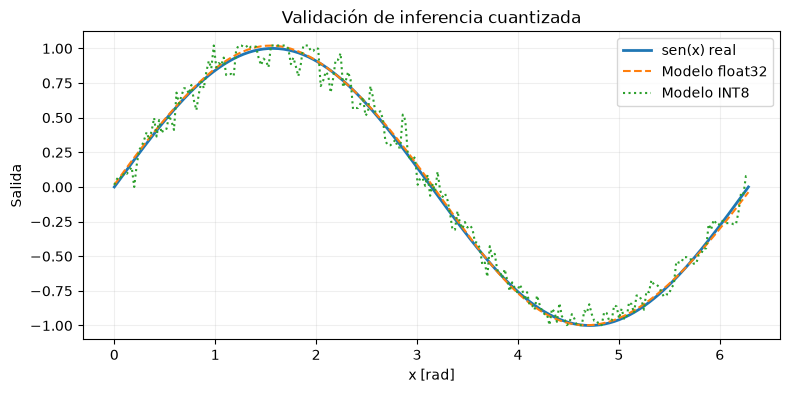

In [15]:
lite = tf.lite.Interpreter(model_content=tflite_model)
lite.allocate_tensors()
inp = lite.get_input_details()[0]
out = lite.get_output_details()[0]
assert inp['dtype'] == np.int8, f"Entrada inesperada: {inp['dtype']}"
assert out['dtype'] == np.int8, f"Salida inesperada: {out['dtype']}"
in_scale, in_zero = inp['quantization']
out_scale, out_zero = out['quantization']
assert in_scale > 0 and out_scale > 0
print('Entrada:', inp['shape'].tolist(), 'INT8, scale=', in_scale, 'zero=', in_zero)
print('Salida: ', out['shape'].tolist(), 'INT8, scale=', out_scale, 'zero=', out_zero)

def predict_tflite(x_values):
    predictions = []
    for value in np.asarray(x_values).reshape(-1):
        q = int(np.clip(np.rint(float(value)/in_scale + in_zero), -128, 127))
        lite.set_tensor(inp['index'], np.array([[q]], dtype=np.int8))
        lite.invoke()
        result = int(lite.get_tensor(out['index']).reshape(-1)[0])
        predictions.append((result - out_zero) * out_scale)
    return np.asarray(predictions, dtype=np.float32)

pred_int8 = predict_tflite(X_test)
metric_int8 = error_metrics(y_true, pred_int8)
print('Modelo INT8:', json.dumps(metric_int8, indent=2))
print('Diferencia RMSE INT8 - float32:', metric_int8['RMSE'] - metric_fp32['RMSE'])

plt.figure(figsize=(9, 4))
plt.plot(X_test[:, 0], y_true, label='sen(x) real', linewidth=2)
plt.plot(X_test[:, 0], pred_fp32, '--', label='Modelo float32')
plt.plot(X_test[:, 0], pred_int8, ':', label='Modelo INT8')
plt.xlabel('x [rad]'); plt.ylabel('Salida'); plt.title('Validación de inferencia cuantizada')
plt.legend(); plt.grid(alpha=.2); plt.show()

## 6. Exportar automáticamente `model.h`

El modelo `.tflite` es binario; **Arduino IDE no lo puede enlazar como una variable por sí solo**. Lo convertimos a `const unsigned char g_model[]`, con alineación de 16 bytes.

**No copies manualmente miles de números:** el siguiente paso genera el archivo a partir del modelo real entrenado y cuantizado.

In [16]:
def tflite_to_header(blob, symbol='g_model'):
    body = '\n'.join(
        '  ' + ', '.join(f'0x{b:02x}' for b in blob[i:i+12]) + ','
        for i in range(0, len(blob), 12)
    )
    return (f'#pragma once\n#include <stdint.h>\n\n'
            f'// Modelo INT8 generado por Google Colab. No editar.\n'
            f'alignas(16) const unsigned char {symbol}[] = {{\n{body}\n}};\n'
            f'const unsigned int {symbol}_len = sizeof({symbol});\n')

header_file = OUTPUT / 'model.h'
header_file.write_text(tflite_to_header(tflite_model), encoding='utf-8')
assert 'alignas(16)' in header_file.read_text()
print('Header generado:', header_file)
print('Primeros 12 bytes:', list(tflite_model[:12]))
print('Tamaño de model.h:', header_file.stat().st_size, 'bytes')

Header generado: tinyml_seno/model.h
Primeros 12 bytes: [32, 0, 0, 0, 84, 70, 76, 51, 0, 0, 0, 0]
Tamaño de model.h: 23176 bytes


## 7. Generar el sketch de Arduino IDE

El sketch incluye el intérprete TFLM mediante `Chirale_TensorFlowLite`, inicializa una **arena de tensores de 24 KiB**, y convierte correctamente los datos `float` a INT8 y viceversa usando los parámetros del propio modelo.

Usamos `AllOpsResolver` para simplificar esta primera práctica. **En un curso avanzado conviene reemplazarlo por `MicroMutableOpResolver` con únicamente las operaciones requeridas** y comparar el tamaño de Flash.

El programa recorre el intervalo $[0,2\pi]$ y emite dos series (`real` y `pred`) al **Serial Plotter**, sin necesidad de sensores. La arena y los kernels pueden ajustarse después de la primera compilación.

In [17]:
SKETCH = r'''// TinyML 2026 | Aproximacion de sin(x) con un modelo INT8 propio.
// Placas objetivo: Arduino Nano 33 BLE Sense / Sense Rev2 (nRF52840).
// Biblioteca: Chirale_TensorFlowLite 2.0.0.
#include <Arduino.h>
#include <math.h>
#include <stdint.h>
#include <Chirale_TensorFlowLite.h>
#include "tensorflow/lite/micro/all_ops_resolver.h"
#include "tensorflow/lite/micro/micro_interpreter.h"
#include "tensorflow/lite/schema/schema_generated.h"
#include "model.h"

constexpr int kTensorArenaSize = 24 * 1024;
alignas(16) uint8_t tensor_arena[kTensorArenaSize];

const tflite::Model* net = nullptr;
tflite::MicroInterpreter* interpreter = nullptr;
TfLiteTensor* input_tensor = nullptr;
TfLiteTensor* output_tensor = nullptr;

void fatal(const char* message) {
  Serial.println(message);
  while (true) { delay(1000); }
}

void setup() {
  Serial.begin(115200);
  unsigned long inicio = millis();
  while (!Serial && millis() - inicio < 3000) { delay(10); }

  net = tflite::GetModel(g_model);
  if (net->version() != TFLITE_SCHEMA_VERSION) {
    fatal("ERROR: version de schema incompatible.");
  }

  static tflite::AllOpsResolver resolver;
  static tflite::MicroInterpreter static_interpreter(
      net, resolver, tensor_arena, kTensorArenaSize);
  interpreter = &static_interpreter;

  if (interpreter->AllocateTensors() != kTfLiteOk) {
    fatal("ERROR: AllocateTensors. Revisar arena/ops/versiones.");
  }
  input_tensor = interpreter->input(0);
  output_tensor = interpreter->output(0);
  if (input_tensor->type != kTfLiteInt8 || output_tensor->type != kTfLiteInt8) {
    fatal("ERROR: se esperaba entrada y salida INT8.");
  }
  if (input_tensor->params.scale <= 0 || output_tensor->params.scale <= 0) {
    fatal("ERROR: escalas de cuantizacion invalidas.");
  }
  Serial.println("Inicializacion completa; abrir Herramientas > Serial Plotter.");
}

void loop() {
  static uint16_t paso = 0;
  constexpr uint16_t kPasos = 128;
  constexpr float kDosPi = 6.28318530718f;
  float x = kDosPi * (float)(paso % kPasos) / (float)(kPasos - 1);
  paso++;

  // Cuantizacion: q = round(x / scale) + zero_point, saturada a [-128,127].
  const float s_in = input_tensor->params.scale;
  const int z_in = input_tensor->params.zero_point;
  int qx = (int)lroundf(x / s_in) + z_in;
  if (qx < -128) qx = -128;
  if (qx >  127) qx =  127;
  input_tensor->data.int8[0] = (int8_t)qx;

  if (interpreter->Invoke() != kTfLiteOk) {
    fatal("ERROR: fallo de inferencia.");
  }

  int8_t qy = output_tensor->data.int8[0];
  float y = (float)(qy - output_tensor->params.zero_point)
            * output_tensor->params.scale;
  float real = sinf(x);

  // Salida apta para Arduino IDE Serial Plotter.
  Serial.print("real:"); Serial.print(real, 4);
  Serial.print(",pred:"); Serial.println(y, 4);
  delay(80);
}'''

sketch_dir = OUTPUT / 'TinyML_Seno_Nano33BLE'
sketch_dir.mkdir(exist_ok=True)
ino_file = sketch_dir / 'TinyML_Seno_Nano33BLE.ino'
ino_file.write_text(SKETCH, encoding='utf-8')
(sketch_dir / 'model.h').write_bytes(header_file.read_bytes())
print('Sketch:', ino_file)
print('Carpeta Arduino:', sketch_dir)
print('Bytes del sketch:', ino_file.stat().st_size)

Sketch: tinyml_seno/TinyML_Seno_Nano33BLE/TinyML_Seno_Nano33BLE.ino
Carpeta Arduino: tinyml_seno/TinyML_Seno_Nano33BLE
Bytes del sketch: 2787


## 8. Instalación de Arduino IDE y biblioteca (pasos detallados)

**A. Instalar Arduino IDE 2.x**

1. Descarga **Arduino IDE 2.x** desde [arduino.cc/en/software](https://www.arduino.cc/en/software) e instálalo en tu computadora (no dentro de Colab).
2. Abre **Herramientas → Placa → Gestor de placas** y busca **Arduino Mbed OS Nano Boards**. Instala ese paquete de soporte.
3. Conecta la tarjeta por USB; en **Herramientas → Placa** selecciona **Arduino Nano 33 BLE** (la opción del núcleo Mbed para Nano 33 BLE / Sense / Sense Rev2 según el paquete instalado). Elige el puerto serie que aparece al conectar la placa.
4. Abre **Herramientas → Administrar bibliotecas** y busca **Chirale**. Instala **Chirale_TensorFlowLite** (versión 2.0.0 si está disponible). En algunos listados el nombre aparece capitalizado como `Chirale_TensorFLowLite`; el header que utiliza el programa es `Chirale_TensorFlowLite.h`.
5. Si la biblioteca no aparece en el Gestor: descarga el ZIP desde [spaziochirale/Chirale_TensorFlowLite](https://github.com/spaziochirale/Chirale_TensorFlowLite) (botón **Code → Download ZIP**) y usa **Programa → Incluir librería → Añadir biblioteca .ZIP…**. Reinicia el IDE si fuera necesario. **No instales simultáneamente varias bibliotecas que exporten las mismas cabeceras de TFLM** (`Arduino_TensorFlowLite` archivada, Chirale, etc.) para evitar colisiones de dependencias.

**B. Abrir el proyecto generado**

6. Ejecuta todas las celdas hasta el final, descarga **`TinyML_Seno_Arduino_Nano33BLE.zip`** y **descomprímelo** (no abras el ZIP directamente como sketch).
7. En Arduino IDE: **Archivo → Abrir → `TinyML_Seno_Nano33BLE/TinyML_Seno_Nano33BLE.ino`**. Comprueba que **`model.h`** esté en la misma carpeta que el archivo `.ino` (lo genera automáticamente este notebook).
8. Haz clic en **Verificar** para compilar y después **Subir**.
9. Abre **Herramientas → Serial Plotter**, configura **115200 baudios** y comprueba las dos curvas `real` y `pred`.

**C. Si trabajas en Ubuntu/Linux**

- Verifica el puerto con `ls /dev/ttyACM* /dev/ttyUSB* 2>/dev/null`.
- Si no tienes permisos para abrir el puerto, suele ayudar: `sudo usermod -aG dialout "$USER"`; luego **cierra sesión y vuelve a iniciarla**. No uses `chmod 777` como solución permanente.
- Si la placa no carga, prueba pulsar dos veces el botón reset para entrar al bootloader y vuelve a elegir el puerto.

**D. Resolución de errores frecuentes**

| Síntoma | Causa posible | Comprobación / solución |
|---|---|---|
| `Chirale_TensorFlowLite.h: No such file` | Biblioteca ausente o instalada en carpeta incorrecta | Reinstalar biblioteca y reiniciar IDE |
| `tensorflow/lite/micro/...: No such file` | Biblioteca equivocada o incompleta | Quitar duplicados y verificar distribución Chirale |
| `schema incompatible` | Modelo y runtime usan esquema TFLite distinto | Revisar versiones del conversor de Colab y del runtime de Arduino |
| `AllocateTensors failed` | Arena insuficiente **o** operador/versiones incompatibles | Aumentar `kTensorArenaSize` y revisar logs/operadores |
| El sketch compila pero no aparece una curva | Puerto/baudios incorrectos, mensaje de error o cable USB de solo carga | Abrir el monitor serie a 115200 y comprobar mensajes |
| Resultados muy alejados de `sin(x)` | Error de cuantización o uso de otro `model.h` | Revisar los metadatos de INT8 y copiar el header generado |

> **Advertencia metodológica:** la biblioteca Chirale proviene de 2024 y no garantiza compatibilidad con todas las versiones futuras del conversor TensorFlow. El notebook valida la inferencia TFLite en Python; **la compilación y la ejecución en la placa son verificaciones que debe realizar cada estudiante**. Si un modelo generado por TensorFlow actual usa versiones de operadores más recientes que la biblioteca Arduino, hay que ajustar la versión de herramientas o reconstruir TFLM, no copiar arbitrariamente bytes a otro formato.

# Guardar y organizar el modelo base

In [18]:
from pathlib import Path
import shutil
import json

# Identificar la raíz del repositorio
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

assert (ROOT / "modelos").is_dir(), (
    "Ejecuta el notebook desde TinyML2 o notebooks/"
)

# Crear directorios
BASE = ROOT / "modelos" / "base"
ARDUINO = ROOT / "arduino" / "baseline" / "TinyML_Seno_Nano33BLE"
RESULTADOS = ROOT / "resultados" / "tablas"

for carpeta in [BASE, ARDUINO, RESULTADOS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Guardar modelo Keras entrenado
model.save(BASE / "seno_base.keras")

# Copiar modelo INT8
shutil.copy2(
    model_file,
    BASE / "M5_int8_completo.tflite"
)

# Copiar archivos para Arduino
shutil.copy2(header_file, ARDUINO / "model.h")
shutil.copy2(
    ino_file,
    ARDUINO / "TinyML_Seno_Nano33BLE.ino"
)

# Registrar información reproducible
metadata = {
    "seed": SEED,
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "epocas": len(history.history["loss"]),
    "parametros": model.count_params(),
    "tflite_int8_bytes": len(tflite_model),
    "rmse_fp32": metric_fp32["RMSE"],
    "rmse_int8": metric_int8["RMSE"]
}

(RESULTADOS / "modelo_base.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("Modelo base y archivos Arduino guardados.")

Modelo base y archivos Arduino guardados.


# T6: Generación de modelos con diferentes estrategias de cuantización

In [1]:
from pathlib import Path
import numpy as np
import tensorflow as tf

# Obtener la raíz del repositorio
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

BASE = ROOT / "modelos" / "base"

# Cargar el modelo entrenado y guardado durante T1
model_base = tf.keras.models.load_model(
    BASE / "seno_base.keras",
    compile=False
)

print("Modelo base cargado correctamente.")
print("Parámetros:", model_base.count_params())
model_base.summary()

I0000 00:00:1793775914.315776  199852 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793775914.602146  199852 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793775916.484298  199852 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Modelo base cargado correctamente.
Parámetros: 321


W0000 00:00:1793775919.055597  199852 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "seno_tinyml"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

## Crear los modelos M1, M2 y M3

Generar los 3 modelos que no necesitan un conjunto representativo de calibracion

### M1: Sin cuantización


In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model_base)

m1 = converter.convert()

(BASE / "M1_fp32.tflite").write_bytes(m1)

print("M1:", len(m1), "bytes")

INFO:tensorflow:Assets written to: /tmp/tmp7hjskvg4/assets


INFO:tensorflow:Assets written to: /tmp/tmp7hjskvg4/assets


Saved artifact at '/tmp/tmp7hjskvg4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140335479792720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796752: TensorSpec(shape=(), dtype=tf.resource, name=None)
M1: 3432 bytes


W0000 00:00:1793776029.485429  199852 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793776029.485446  199852 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793776029.485813  199852 reader.cc:83] Reading SavedModel from: /tmp/tmp7hjskvg4
I0000 00:00:1793776029.486127  199852 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793776029.486131  199852 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp7hjskvg4
I0000 00:00:1793776029.490143  199852 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793776029.490647  199852 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793776029.518222  199852 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp7hjskvg4
I0000 00:00:1793776029.524780  199852 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 38975 microseconds.
I0000 00:00:1793776029.544808  199852

### M2: Cuantización de rango dinámico
Activar optimizaciones predeterminadas sin proporcionar un conjunto de calibracion.

In [ ]:

converter = tf.lite.TFLiteConverter.from_keras_model(model_base)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

m2 = converter.convert()

(BASE / "M2_dinamico.tflite").write_bytes(m2)

print("M2:", len(m2), "bytes")

INFO:tensorflow:Assets written to: /tmp/tmp3ums0og3/assets


INFO:tensorflow:Assets written to: /tmp/tmp3ums0og3/assets


Saved artifact at '/tmp/tmp3ums0og3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140335479792720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796752: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1793776093.851362  199852 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793776093.851376  199852 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793776093.851465  199852 reader.cc:83] Reading SavedModel from: /tmp/tmp3ums0og3


M2: 3432 bytes


I0000 00:00:1793776093.851796  199852 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793776093.851800  199852 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp3ums0og3
I0000 00:00:1793776093.853648  199852 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793776093.867959  199852 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp3ums0og3
I0000 00:00:1793776093.872743  199852 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 21288 microseconds.


### M3: Cuantización Float16

In [4]:
converter = tf.lite.TFLiteConverter.from_keras_model(model_base)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

m3 = converter.convert()

(BASE / "M3_fp16.tflite").write_bytes(m3)

print("M3:", len(m3), "bytes")

INFO:tensorflow:Assets written to: /tmp/tmpbch0nj4q/assets


INFO:tensorflow:Assets written to: /tmp/tmpbch0nj4q/assets


Saved artifact at '/tmp/tmpbch0nj4q'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140335479792720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796752: TensorSpec(shape=(), dtype=tf.resource, name=None)
M3: 3696 bytes


W0000 00:00:1793776211.784065  199852 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793776211.784085  199852 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793776211.784289  199852 reader.cc:83] Reading SavedModel from: /tmp/tmpbch0nj4q
I0000 00:00:1793776211.784633  199852 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793776211.784638  199852 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpbch0nj4q
I0000 00:00:1793776211.787800  199852 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793776211.808090  199852 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpbch0nj4q
I0000 00:00:1793776211.814869  199852 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 30590 microseconds.


### M4
Conserva una interfaz Float32 pero a diferencia del M5, utiliza operaciones internas cuantizadas.

In [ ]:
# Definimos el conjunto representativo, utilizando el mismo intervalo que el entrenamiento original.

def representative_data():
    valores = np.linspace(
        0.0, 2 * np.pi, 256, dtype=np.float32
    )

    for x in valores:
        yield [np.array([[x]], dtype=np.float32)]

In [6]:
# Convertimos
converter = tf.lite.TFLiteConverter.from_keras_model(model_base)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Entrada y salida Float32
converter.inference_input_type = tf.float32
converter.inference_output_type = tf.float32

m4 = converter.convert()

(BASE / "M4_int8_io_float.tflite").write_bytes(m4)

print("M4:", len(m4), "bytes")

INFO:tensorflow:Assets written to: /tmp/tmpg65_fgwx/assets


INFO:tensorflow:Assets written to: /tmp/tmpg65_fgwx/assets


Saved artifact at '/tmp/tmpg65_fgwx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140335479792720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479793104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140335479796752: TensorSpec(shape=(), dtype=tf.resource, name=None)
M4: 4080 bytes


/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793776412.236420  199852 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793776412.236444  199852 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793776412.236622  199852 reader.cc:83] Reading SavedModel from: /tmp/tmpg65_fgwx
I0000 00:00:1793776412.237063  199852 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793776412.237068  199852 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpg65_fgwx
I0000 00:00:1793776412.240294  199852 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793776412.259356  199852 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpg65_fgwx
I0000 00:00:1793776412.265955  199852 loader.cc:471] SavedModel load for 

In [7]:
modelos = {
    "M1": BASE / "M1_fp32.tflite",
    "M2": BASE / "M2_dinamico.tflite",
    "M3": BASE / "M3_fp16.tflite",
    "M4": BASE / "M4_int8_io_float.tflite",
    "M5": BASE / "M5_int8_completo.tflite",
}

for nombre, archivo in modelos.items():

    assert archivo.exists(), f"Falta el modelo {nombre}"

    lite = tf.lite.Interpreter(model_path=str(archivo))
    lite.allocate_tensors()

    entrada = lite.get_input_details()[0]
    salida = lite.get_output_details()[0]

    print(
        nombre,
        "| Tamaño:", archivo.stat().st_size, "bytes",
        "| Entrada:", entrada["dtype"].__name__,
        "| Salida:", salida["dtype"].__name__
    )

M1 | Tamaño: 3432 bytes | Entrada: float32 | Salida: float32
M2 | Tamaño: 3432 bytes | Entrada: float32 | Salida: float32
M3 | Tamaño: 3696 bytes | Entrada: float32 | Salida: float32
M4 | Tamaño: 4080 bytes | Entrada: float32 | Salida: float32
M5 | Tamaño: 3728 bytes | Entrada: int8 | Salida: int8


/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [8]:
for nombre in ["M1", "M2", "M3", "M4", "M5"]:
    print(f"\n{'='*50}")
    print(f"ANÁLISIS DEL MODELO {nombre}")
    print(f"{'='*50}")

    tf.lite.experimental.Analyzer.analyze(
        model_path=str(modelos[nombre])
    )


ANÁLISIS DEL MODELO M1
=== /home/jrgels/Documents/Maestria PCIC/3er Semestre/TinyML/Tareas/TinyML2/modelos/base/M1_fp32.tflite ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the FULLY_CONNECTED op takes
tensor #0 and tensor #5 and tensor #6 as input and produces tensor #7 as output.

Subgraph#0 main(T#0) -> [T#11]
  Op#0 FULLY_CONNECTED(T#0, T#5, T#6) -> [T#7]
  Op#1 TANH(T#7) -> [T#8]
  Op#2 FULLY_CONNECTED(T#8, T#4, T#2) -> [T#9]
  Op#3 TANH(T#9) -> [T#10]
  Op#4 FULLY_CONNECTED(T#10, T#3, T#1) -> [T#11]

Tensors of Subgraph#0
  T#0(serving_default_input_layer_3:0) shape_signature:[-1, 1], type:FLOAT32
  T#1(seno_tinyml_1/dense_11_1/Add) shape:[1], type:FLOAT32 RO 4 bytes, buffer: 2, data:[0.0541668]
  T#2(seno_tinyml_1/dense_10_1/BiasAdd) shape:[16], type:FLOAT32 RO 64 bytes, buffer: 3, data:[-0.133591, 0.0130946, -0.0792323, -0.0743982, -0.0541748, ...]
  T#3(seno_tinyml_1/dense_11_1/MatM

# Tabla comparativa de tamaños de los modelos

In [10]:
import pandas as pd

tamano_m1 = modelos["M1"].stat().st_size

df_tamanos = pd.DataFrame([
    {
        "Modelo": nombre,
        "Tamaño (bytes)": archivo.stat().st_size,
        "Reducción (%)": round(
            (tamano_m1 - archivo.stat().st_size)
            / tamano_m1 * 100, 2
        )
    }
    for nombre, archivo in modelos.items()
])

ruta = ROOT / "resultados" / "tablas" / "T6_tamanos_modelos.csv"
ruta.parent.mkdir(parents=True, exist_ok=True)

df_tamanos.to_csv(ruta, index=False)

display(df_tamanos)

,Modelo,Tamaño (bytes),Reducción (%)
0,M1,3432,0.00
1,M2,3432,0.00
2,M3,3696,-7.69
3,M4,4080,-18.88
4,M5,3728,-8.62


## Comparacion de estrategias de cuantización y analisis del FlatBuffer

### Analisis de operadores y tensores

In [11]:
from collections import Counter
import pandas as pd
import tensorflow as tf

resultados = []

for nombre, archivo in modelos.items():

    lite = tf.lite.Interpreter(
        model_path=str(archivo)
    )

    lite.allocate_tensors()

    # Obtener información de los tensores
    tensores = lite.get_tensor_details()

    # Obtener información de los operadores
    operadores = lite._get_ops_details()

    # Contar los tipos de datos
    tipos = Counter(
        tensor["dtype"].__name__
        for tensor in tensores
    )

    # Contar operadores por tipo
    ops = Counter(
        op["op_name"]
        for op in operadores
    )

    resultados.append({
        "Modelo": nombre,
        "Tamaño (bytes)": archivo.stat().st_size,
        "N.º tensores": len(tensores),
        "N.º operadores": len(operadores),
        "Float32": tipos.get("float32", 0),
        "Float16": tipos.get("float16", 0),
        "INT8": tipos.get("int8", 0),
        "INT32": tipos.get("int32", 0),
        "Operadores": ", ".join(
            f"{op} ({n})"
            for op, n in ops.items()
        )
    })

df_estructura = pd.DataFrame(resultados)

display(df_estructura)

/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Modelo,Tamaño (bytes),N.º tensores,N.º operadores,Float32,Float16,INT8,INT32,Operadores
0,M1,3432,12,6,12,0,0,0,"FULLY_CONNECTED (3), TANH (2), DELEGATE (1)"
1,M2,3432,12,6,12,0,0,0,"FULLY_CONNECTED (3), TANH (2), DELEGATE (1)"
2,M3,3696,18,12,12,6,0,0,"DEQUANTIZE (6), FULLY_CONNECTED (3), TANH (2),..."
3,M4,4080,14,8,2,0,9,3,"QUANTIZE (1), FULLY_CONNECTED (3), TANH (2), D..."
4,M5,3728,12,6,0,0,9,3,"FULLY_CONNECTED (3), TANH (2), DELEGATE (1)"


In [12]:
# Guardar resultados en CSV
ruta = (
    ROOT / "resultados" / "tablas"
    / "T7_estructura_modelos.csv"
)

ruta.parent.mkdir(parents=True, exist_ok=True)

df_estructura.to_csv(
    ruta,
    index=False
)

print("Tabla guardada:", ruta)

Tabla guardada: /home/jrgels/Documents/Maestria PCIC/3er Semestre/TinyML/Tareas/TinyML2/resultados/tablas/T7_estructura_modelos.csv


### Analisis de los pesos y sesgos por capa

In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf

filas_parametros = []

for nombre, archivo in modelos.items():

    lite = tf.lite.Interpreter(
        model_path=str(archivo),
        experimental_preserve_all_tensors=True
    )
    lite.allocate_tensors()

    tensores = {
        t["index"]: t
        for t in lite.get_tensor_details()
    }

    operadores = lite._get_ops_details()

    # Identificar qué operador produce cada tensor
    productores = {
        int(idx): op
        for op in operadores
        for idx in op["outputs"]
        if idx >= 0
    }

    # Rastrear el tensor original antes de DEQUANTIZE
    def tensor_almacenado(idx):
        idx = int(idx)

        while idx in productores:
            op = productores[idx]

            if op["op_name"] != "DEQUANTIZE":
                break

            idx = int(op["inputs"][0])

        return tensores[idx]

    capas = [
        op for op in operadores
        if op["op_name"] == "FULLY_CONNECTED"
    ]

    for numero, op in enumerate(capas, start=1):

        # FULLY_CONNECTED recibe:
        # [activaciones, pesos, sesgos]
        idx_pesos = int(op["inputs"][1])
        idx_sesgos = int(op["inputs"][2])

        pesos = tensor_almacenado(idx_pesos)
        sesgos = tensor_almacenado(idx_sesgos)

        # Tipo de dato utilizado por el operador
        tipo_operacion = tensores[idx_pesos]["dtype"].__name__

        # Parámetros de cuantización
        q_pesos = pesos["quantization_parameters"]
        escalas = q_pesos["scales"]

        filas_parametros.append({
            "Modelo": nombre,
            "Capa": f"Dense {numero}",
            "Pesos": int(np.prod(pesos["shape"])),
            "Sesgos": int(np.prod(sesgos["shape"])),
            "Tipo pesos": pesos["dtype"].__name__,
            "Tipo sesgos": sesgos["dtype"].__name__,
            "Tipo usado por FC": tipo_operacion,
            "N.º escalas pesos": len(escalas)
        })

df_parametros = pd.DataFrame(filas_parametros)

display(df_parametros)

/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:465: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


,Modelo,Capa,Pesos,Sesgos,Tipo pesos,Tipo sesgos,Tipo usado por FC,N.º escalas pesos
0,M1,Dense 1,16,16,float32,float32,float32,0
1,M1,Dense 2,256,16,float32,float32,float32,0
2,M1,Dense 3,16,1,float32,float32,float32,0
3,M2,Dense 1,16,16,float32,float32,float32,0
4,M2,Dense 2,256,16,float32,float32,float32,0
5,M2,Dense 3,16,1,float32,float32,float32,0
6,M3,Dense 1,16,16,float32,float32,float32,0
7,M3,Dense 2,256,16,float32,float32,float32,0
8,M3,Dense 3,16,1,float32,float32,float32,0
9,M4,Dense 1,16,16,int8,int32,int8,16


In [14]:
# Guardar resultados en CSV
ruta = (
    ROOT / "resultados" / "tablas"
    / "T7_parametros_por_capa.csv"
)

df_parametros.to_csv(ruta, index=False)

print("Tabla guardada:", ruta)

Tabla guardada: /home/jrgels/Documents/Maestria PCIC/3er Semestre/TinyML/Tareas/TinyML2/resultados/tablas/T7_parametros_por_capa.csv


In [15]:
# Verificar la representacion Float16 de M3

lite = tf.lite.Interpreter(
    model_path=str(modelos["M3"]),
    experimental_preserve_all_tensors=True
)
lite.allocate_tensors()

tensores = {
    t["index"]: t
    for t in lite.get_tensor_details()
}

print("Conversiones del modelo M3:\n")

for op in lite._get_ops_details():
    if op["op_name"] == "DEQUANTIZE":
        origen = tensores[int(op["inputs"][0])]
        destino = tensores[int(op["outputs"][0])]

        print(
            f"{origen['name']}: "
            f"{origen['dtype'].__name__} "
            f"→ {destino['dtype'].__name__}"
        )

Conversiones del modelo M3:

seno_tinyml_1/dense_11_1/Add: float16 → float32
seno_tinyml_1/dense_10_1/BiasAdd: float16 → float32
seno_tinyml_1/dense_11_1/MatMul: float16 → float32
seno_tinyml_1/dense_10_1/MatMul: float16 → float32
seno_tinyml_1/dense_9_1/MatMul: float16 → float32
seno_tinyml_1/dense_9_1/BiasAdd: float16 → float32


/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:465: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


### Analisis de parametros de cuantizacion

In [18]:
filas_quant = []

for nombre in ["M4", "M5"]:

    lite = tf.lite.Interpreter(
        model_path=str(modelos[nombre]),
        experimental_preserve_all_tensors=True
    )
    lite.allocate_tensors()

    entradas = {
        t["index"] for t in lite.get_input_details()
    }
    salidas = {
        t["index"] for t in lite.get_output_details()
    }

    for tensor in lite.get_tensor_details():

        q = tensor["quantization_parameters"]
        scales = q["scales"]
        zeros = q["zero_points"]

        if len(scales) == 0:
            continue

        if tensor["index"] in entradas:
            categoria = "Entrada"
        elif tensor["index"] in salidas:
            categoria = "Salida"
        else:
            categoria = "Interno"

        filas_quant.append({
            "Modelo": nombre,
            "Tensor": tensor["name"],
            "Categoría": categoria,
            "Tipo": tensor["dtype"].__name__,
            "N.º escalas": len(scales),
            "Scale mínimo": float(np.min(scales)),
            "Scale máximo": float(np.max(scales)),
            "Zero points": str(np.unique(zeros).tolist()),
            "Eje cuantizado": int(q["quantized_dimension"])
        })

df_quant = pd.DataFrame(filas_quant)

display(df_quant)

ruta = (
    ROOT / "resultados" / "tablas"
    / "T7_parametros_cuantizacion.csv"
)

df_quant.to_csv(ruta, index=False)

/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:465: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


,Modelo,Tensor,Categoría,Tipo,N.º escalas,Scale mínimo,Scale máximo,Zero points,Eje cuantizado
0,M4,seno_tinyml_1/dense_11_1/Add,Interno,int32,1,0.000113,0.000113,[0],0
1,M4,seno_tinyml_1/dense_11_1/MatMul,Interno,int8,1,0.014401,0.014401,[0],0
2,M4,seno_tinyml_1/dense_10_1/BiasAdd,Interno,int32,16,0.000028,0.000057,[0],0
3,M4,seno_tinyml_1/dense_10_1/MatMul,Interno,int8,16,0.003558,0.007306,[0],0
4,M4,seno_tinyml_1/dense_9_1/BiasAdd,Interno,int32,16,0.000024,0.000186,[0],0
5,M4,seno_tinyml_1/dense_9_1/MatMul,Interno,int8,16,0.000975,0.007531,[0],0
6,M4,tfl.quantize,Interno,int8,1,0.024640,0.024640,[-128],0
7,M4,seno_tinyml_1/dense_9_1/MatMul;seno_tinyml_1/d...,Interno,int8,1,0.041064,0.041064,[-4],0
8,M4,seno_tinyml_1/dense_9_1/Tanh,Interno,int8,1,0.007812,0.007812,[0],0
9,M4,seno_tinyml_1/dense_10_1/MatMul;seno_tinyml_1/...,Interno,int8,1,0.018104,0.018104,[-11],0


## Evaluar RMSE y MAE de los cinco modelos
Se evalúan los modelos M1–M5 utilizando el mismo conjunto de
prueba para calcular RMSE y MAE, comparando sus predicciones
con los valores reales de la función seno.

In [20]:
import numpy as np
import pandas as pd
import tensorflow as tf

def predecir_tflite(ruta_modelo, X):

    lite = tf.lite.Interpreter(
        model_path=str(ruta_modelo)
    )

    lite.allocate_tensors()

    inp = lite.get_input_details()[0]
    out = lite.get_output_details()[0]

    predicciones = []

    for x in np.asarray(X).reshape(-1):

        # Preparar la entrada
        if inp["dtype"] == np.int8:
            scale, zero = inp["quantization"]

            q = np.clip(
                np.rint(float(x) / scale + zero),
                -128, 127
            )

            entrada = np.array(
                [[q]], dtype=np.int8
            )

        else:
            entrada = np.array(
                [[x]], dtype=inp["dtype"]
            )

        # Ejecutar inferencia
        lite.set_tensor(inp["index"], entrada)
        lite.invoke()

        resultado = lite.get_tensor(
            out["index"]
        ).reshape(-1)[0]

        # Descuantizar salida cuando sea necesario
        if out["dtype"] == np.int8:
            scale, zero = out["quantization"]
            resultado = (
                int(resultado) - zero
            ) * scale

        predicciones.append(float(resultado))

    return np.asarray(
        predicciones, dtype=np.float32
    )


# Generar 256 muestras de prueba entre 0 y 2π
X_eval = np.linspace(
    0.0,
    2 * np.pi,
    256,
    dtype=np.float32
).reshape(-1, 1)

# Calcular los valores reales de la función seno
y_eval = np.sin(X_eval).reshape(-1)

print("Dimensión de X_eval:", X_eval.shape)
print("Dimensión de y_eval:", y_eval.shape)
resultados_precision = []
predicciones_modelos = {}

for nombre, archivo in modelos.items():

    y_pred = predecir_tflite(
        archivo, X_eval
    )

    predicciones_modelos[nombre] = y_pred

    rmse = np.sqrt(
        np.mean((y_eval - y_pred) ** 2)
    )

    mae = np.mean(
        np.abs(y_eval - y_pred)
    )

    resultados_precision.append({
        "Modelo": nombre,
        "Tamaño (bytes)": archivo.stat().st_size,
        "RMSE": float(rmse),
        "MAE": float(mae)
    })

df_precision = pd.DataFrame(resultados_precision)

display(df_precision)

Dimensión de X_eval: (256, 1)
Dimensión de y_eval: (256,)


/home/jrgels/miniconda3/envs/IA/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Modelo,Tamaño (bytes),RMSE,MAE
0,M1,3432,0.013901,0.011784
1,M2,3432,0.013901,0.011784
2,M3,3696,0.014199,0.012181
3,M4,4080,0.075025,0.059884
4,M5,3728,0.075025,0.059884


### Comparación de tamaños y precisión

Se calcula el porcentaje de reducción del tamaño de cada modelo
respecto a M1 (Float32), utilizando:

$$
R = \frac{M_{\mathrm{FP32}} - M_{\mathrm{cuantizado}}}
{M_{\mathrm{FP32}}} \times 100
$$

Un valor negativo indica que el archivo es mayor que el modelo
original.

In [21]:
# Tomar M1 como referencia
tamano_m1 = df_precision.loc[
    df_precision["Modelo"] == "M1",
    "Tamaño (bytes)"
].iloc[0]

rmse_m1 = df_precision.loc[
    df_precision["Modelo"] == "M1",
    "RMSE"
].iloc[0]

# Construir tabla comparativa
df_comparacion = df_precision.copy()

df_comparacion["Reducción (%)"] = (
    (tamano_m1 - df_comparacion["Tamaño (bytes)"])
    / tamano_m1 * 100
)

df_comparacion["Diferencia RMSE"] = (
    df_comparacion["RMSE"] - rmse_m1
)

# Reorganizar columnas
df_comparacion = df_comparacion[
    [
        "Modelo",
        "Tamaño (bytes)",
        "Reducción (%)",
        "RMSE",
        "MAE",
        "Diferencia RMSE"
    ]
]

display(df_comparacion.round(6))

# Guardar resultados
ruta = (
    ROOT / "resultados" / "tablas"
    / "T7_comparacion_modelos.csv"
)

ruta.parent.mkdir(parents=True, exist_ok=True)

df_comparacion.to_csv(ruta, index=False)

print("Tabla guardada:", ruta)

,Modelo,Tamaño (bytes),Reducción (%),RMSE,MAE,Diferencia RMSE
0,M1,3432,0.000000,0.013901,0.011784,0.000000
1,M2,3432,0.000000,0.013901,0.011784,0.000000
2,M3,3696,-7.692308,0.014199,0.012181,0.000299
3,M4,4080,-18.881119,0.075025,0.059884,0.061124
4,M5,3728,-8.624709,0.075025,0.059884,0.061124


Tabla guardada: /home/jrgels/Documents/Maestria PCIC/3er Semestre/TinyML/Tareas/TinyML2/resultados/tablas/T7_comparacion_modelos.csv


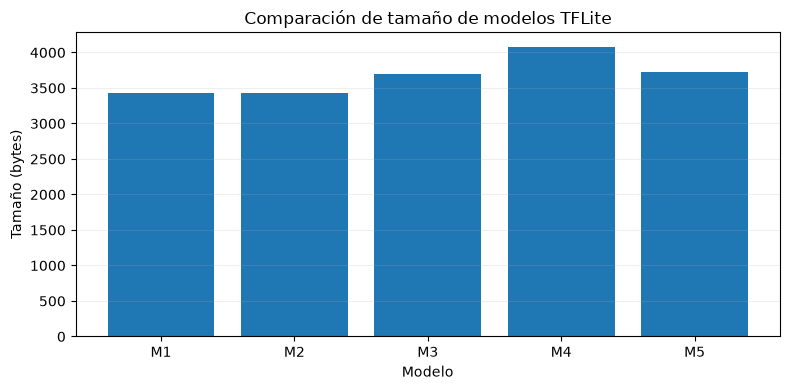

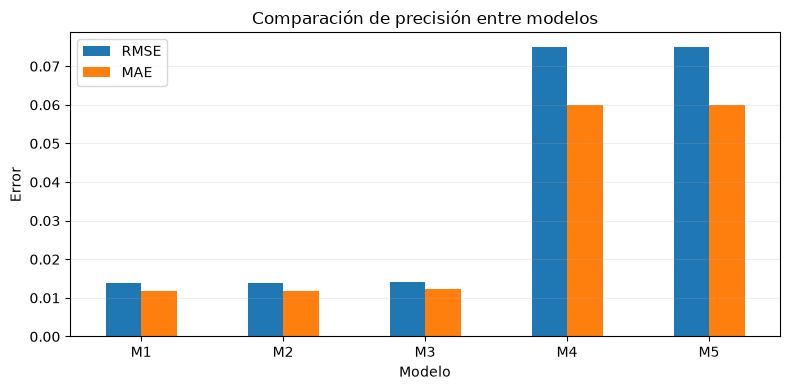

In [22]:
# Generar graficas
import matplotlib.pyplot as plt

GRAFICAS = ROOT / "resultados" / "graficas"
GRAFICAS.mkdir(parents=True, exist_ok=True)

# Gráfica 1: tamaños
plt.figure(figsize=(8, 4))

plt.bar(
    df_comparacion["Modelo"],
    df_comparacion["Tamaño (bytes)"]
)

plt.xlabel("Modelo")
plt.ylabel("Tamaño (bytes)")
plt.title("Comparación de tamaño de modelos TFLite")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    GRAFICAS / "T7_tamanos.png",
    dpi=300
)
plt.show()


# Gráfica 2: errores
df_comparacion.plot(
    x="Modelo",
    y=["RMSE", "MAE"],
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.ylabel("Error")
plt.title("Comparación de precisión entre modelos")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    GRAFICAS / "T7_errores.png",
    dpi=300
)
plt.show()